# ***Assignment 2E, 2026 - Black-box VI for a Poisson–Gamma model (Question 2.3.11)***

In Question 2.3.9 you derived the naive BBVI gradient for the model
$$
x_n\mid\lambda\overset{\text{iid}}{\sim}\mathrm{Poisson}(\lambda),\quad n=1,\dots,N,\qquad \lambda\sim\mathrm{Gamma}(\alpha_0,\beta_0)\ \text{(shape, rate)},
$$
with variational distribution $q(\lambda)=\mathrm{Exponential}(\theta)$. Here you implement it on real count data, add the control variate of Ranganath et al. (2014), and repeat the experiment with a richer family $q(\lambda)=\mathrm{Gamma}(a,b)$.

Because the model is conjugate, the exact posterior $\mathrm{Gamma}(\alpha_0+\sum_n x_n,\ \beta_0+N)$ and the ELBO of both variational families are available in closed form. You can therefore check whether your black-box estimates are correct, even though BBVI itself never uses these formulas.

Use **numpy and scipy only**, and do not change the seeds.

**Data.** Capital Bikeshare, Washington D.C., 2011 (Fanaee-T & Gama, 2013; copy from the ISLP package, file `data/Bikeshare.csv`). We model the number of *registered* users starting a trip between 4 and 5 a.m. on the first $N=30$ working days of the year. At this hour the counts are small and roughly Poisson-like (they are, if anything, slightly under-dispersed).

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL.ImageOps import scale
from scipy.special import gammaln, digamma, h1vp
from scipy.stats import gamma as gamma_dist

SEED = 2026  # Do not change the seed

## Provided code

In [9]:
bikes = pd.read_csv("data/Bikeshare.csv")
counts = bikes.loc[(bikes["hr"] == 4) & (bikes["workingday"] == 1), "registered"].to_numpy()
x = counts[:30]
N, sum_x = len(x), x.sum()
print(f"N = {N}, counts: {x}")
print(f"mean = {x.mean():.2f}, variance = {x.var(ddof=1):.2f}")

ALPHA0, BETA0 = 2.0, 0.5    # Gamma prior (shape, rate): prior mean 4 riders per hour
A_POST, B_POST = ALPHA0 + sum_x, BETA0 + N
print(f"exact posterior: Gamma({A_POST:.0f}, {B_POST:.1f}), mean {A_POST / B_POST:.3f}")


def log_joint(lam, x=x):
    # log p(x, lambda) for an array of lambda values
    lam = np.asarray(lam, dtype=float)
    return (np.sum(x) * np.log(lam) - len(x) * lam - np.sum(gammaln(x + 1))
            + ALPHA0 * np.log(BETA0) - gammaln(ALPHA0) + (ALPHA0 - 1) * np.log(lam) - BETA0 * lam)


def elbo_gamma(a, b, x=x):
    # Closed-form ELBO for q(lambda) = Gamma(a, b) (rate b). Exponential(theta) is Gamma(1, theta).
    E_lam, E_log_lam = a / b, digamma(a) - np.log(b)
    entropy = a - np.log(b) + gammaln(a) + (1 - a) * digamma(a)
    return (np.sum(x) * E_log_lam - len(x) * E_lam - np.sum(gammaln(x + 1))
            + ALPHA0 * np.log(BETA0) - gammaln(ALPHA0) + (ALPHA0 - 1) * E_log_lam - BETA0 * E_lam + entropy)


def log_evidence(x=x):
    # Closed-form log p(x); KL(q || posterior) = log p(x) - ELBO
    a, b = ALPHA0 + np.sum(x), BETA0 + len(x)
    return (ALPHA0 * np.log(BETA0) - gammaln(ALPHA0) + gammaln(a) - a * np.log(b) - np.sum(gammaln(x + 1)))


def control_variate_scaling(f, h):
    # Leave-one-out estimate of a* = Cov(f, h) / Var(h) for each sample s, computed without sample s.
    # Estimating a* from the same samples it is applied to makes the estimator biased for small S;
    # leaving sample s out keeps E[f_s - a_{-s} h_s] = E[f] because a_{-s} is independent of z_s.
    S = len(f)
    n = S - 1
    mean_f = (f.sum() - f) / n
    mean_h = (h.sum() - h) / n
    cov = ((f * h).sum() - f * h - n * mean_f * mean_h) / (n - 1)
    var = ((h * h).sum() - h * h - n * mean_h**2) / (n - 1)
    return cov / var


def adagrad_ascent(grad_fn, omega0, n_iter, lr, rng):
    # Stochastic gradient ascent with AdaGrad step sizes on unconstrained parameters omega.
    omega, G = np.array(omega0, dtype=float), np.zeros(len(omega0))
    trace = np.zeros((n_iter, len(omega0)))
    for t in range(n_iter):
        g = grad_fn(omega, rng)
        G += g**2
        omega = omega + lr * g / (np.sqrt(G) + 1e-8)
        trace[t] = omega
    return trace

N = 30, counts: [1 2 2 1 1 2 4 1 1 1 1 1 2 1 1 3 1 2 1 1 1 1 1 0 1 0 0 2 2 1]
mean = 1.30, variance = 0.70
exact posterior: Gamma(41, 30.5), mean 1.344


### Part (a): naive BBVI with $q(\lambda)=\mathrm{Exponential}(\theta)$

We optimise the unconstrained parameter $\omega=\log\theta$, so by the chain rule $\nabla_\omega\log q=\theta\,\nabla_\theta\log q$.

Implement `grad_exponential(omega, rng, S, control_variate=False)`, which returns the BBVI estimate of $\nabla_\omega\mathcal L$ from $S$ samples $z_s\sim q$ (Ranganath et al., Algorithm 1 for `control_variate=False`).

Then run `adagrad_ascent` for 3000 iterations with $S=10$, learning rate 0.5 and $\omega_0=0$. Plot $\theta_t$ together with the value $\theta^\star$ that maximises the closed-form ELBO. Find $\theta^\star$ numerically with `elbo_gamma(1, theta)` on a grid, or derive it.

Compare $\mathbb E_q[\lambda]=1/\theta^\star$ with the exact posterior mean, and compare the variance of $q$ with the posterior variance. What does this say about the Exponential family as a variational family here?

In [1]:
def grad_exponential(omega, rng, S=10, control_variate=False):
    theta = np.exp(omega)
    z = rng.exponential(scale=1/theta,size=S)
    h = (1/theta-z)*theta
    f = h*(log_joint(z)- np.log(theta)+theta*z)
    if control_variate:
        a = control_variate_scaling(f,h)
        f = f - a*h
    return np.array([f.mean()])

In [2]:
# Run BBVI, plot theta_t and theta*, and compare q with the exact posterior
S=10
rate = 0.5
nb_iter = 3000
omega0 = [0.0]
rng = np.random.default_rng(SEED)
grid = np.linspace(1e-3,1.0,200000) #not 0 otherwise theta_star = 0.

#Run BBVI
grad_fn = lambda omega,rng : grad_exponential(omega, rng, S, control_variate=False)
adagrad_trace = adagrad_ascent(grad_fn, omega0, nb_iter, rate,rng)

#theta_t
theta_t = np.exp(adagrad_trace[:,0])

#theta*

elbo = elbo_gamma(1.0, grid)
theta_star = grid[np.argmax(elbo)]

#plot
plt.figure()
plt.plot(theta_t, label = "theta_t")
plt.axhline(theta_star,color= "red", label="theta_star")
plt.legend()

#compare q with the exact posterior
post_mean = A_POST/B_POST
post_var = A_POST/B_POST**2
q_mean = 1/theta_star
q_var = 1/theta_star**2

print(f"q_mean (rounded) : {np.round(q_mean,3)} and post_mean (rounded) : {np.round(post_mean,3)}, i.e. a rate of {np.round(q_mean/post_mean,0)}")
print(f"q_var (rounded) : {np.round(q_var,3)} and post_var (rounded) : {np.round(post_var,3)}, i.e. a rate of {np.round(q_var/post_var,0)}")

NameError: name 'np' is not defined

We observe that $\theta_t$ is converging to $\theta^*$. Let us compare the mean and the var of $q$ and the posterior.

The ELBO of the exponential is:
$$
\mathcal{L}(\theta) = -A_{POST}\log \theta-\frac{B_{POST}}{\theta}
$$

i.e., $$
\mathcal{L}'(\theta) = -\frac{A_{POST}}{\theta}+ \frac{B_{POST}}{\theta^2}=0
$$

So, $\theta^*=\frac{B_{POST}}{A_{POST}}$

Hence, because $q\sim \mathcal{E}xponential(\theta)$, then we know the expectation and the variance, so:


\begin{cases}
\mathbb{E}_{q}[\lambda] = \frac{A_{POST}}{B_{POST}} = \mathbb{E}[\lambda|x] \\
\mathbb{V}_q[\lambda] =\frac{A_{POST}^2}{B_{POST}^2} =A_{POST} \mathbb{V}[\lambda|x]
\end{cases}


So, if $A_{POST}\ne1$, the exponential family cannot recover the exact posterior. Therefore, the exponential variational family is too restrictive.

### Part (b): control variates

Extend `grad_exponential` with the control variate of Ranganath et al. (2014, Section 3.2): $h(z)=\nabla_\omega\log q(z)$, which has expectation zero, and scaling $\hat a=\widehat{\mathrm{Cov}}(f,h)/\widehat{\mathrm{Var}}(h)$ estimated from the $S$ samples with the provided `control_variate_scaling`, which leaves each sample out of its own scaling so that the estimator stays unbiased (`control_variate=True`).

At $\theta\in\{0.5\,\theta^\star,\ \theta^\star,\ 2\,\theta^\star\}$, estimate the variance of the gradient estimator with and without the control variate from 2000 independent estimates with $S=10$, and report the results in a table. Rerun part (a) with the control variate and overlay the two traces. Explain why this control variate reduces the variance.

Theta : 0.37195003725018627
Mean grad exp true : 40.01680678541715
Mean grad exp false : 38.44101701211186
Var grad exp true : 2454.617171458931
Var grad exp false : 4662.0836094404585

Theta : 0.7439000745003725
Mean grad exp true : 0.4842322011468605
Mean grad exp false : -1.0826677909027564
Var grad exp true : 404.3261126627556
Var grad exp false : 1279.3174073841603

Theta : 1.487800149000745
Mean grad exp true : -20.461827836069315
Mean grad exp false : -20.48809939559538
Var grad exp true : 250.1092680704906
Var grad exp false : 628.7606471858184



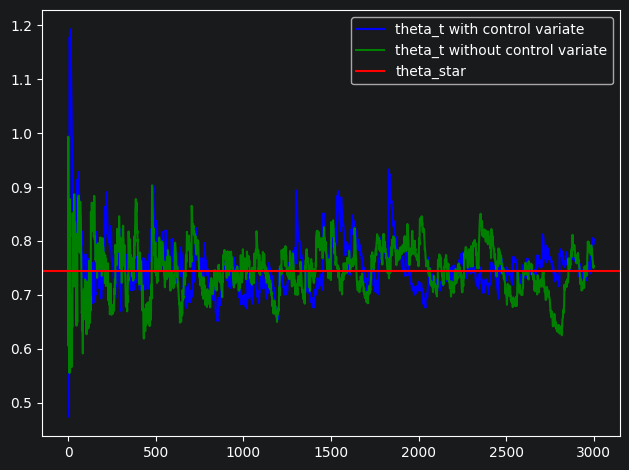

In [5]:
# Run BBVI, plot theta_t and theta*, and compare q with the exact posterior
S=10
rate = 0.5
n = 2000
nb_iter = 3000
omega0 = [0.0]
rng = np.random.default_rng(SEED)
grid = np.linspace(1e-3,1.0,200000) #not 0 otherwise theta_star = 0.

#Run BBVI
grad_fn = lambda omega,rng : grad_exponential(omega, rng, S, control_variate=True)
adagrad_trace = adagrad_ascent(grad_fn, omega0, nb_iter, rate,rng)
theta_t_control_variate = np.exp(adagrad_trace[:,0])

grad_fn = lambda omega,rng : grad_exponential(omega, rng, S, control_variate=False)
adagrad_trace = adagrad_ascent(grad_fn, omega0, nb_iter, rate,rng)
theta_t_no_control_variate = np.exp(adagrad_trace[:,0])

#theta*
elbo = elbo_gamma(1.0, grid)
theta_star = grid[np.argmax(elbo)]

#plot
plt.figure()
plt.plot(theta_t_control_variate, color = "blue",label = "theta_t with control variate")
plt.plot(theta_t_no_control_variate, color = "green",label = "theta_t without control variate")
plt.axhline(theta_star,color= "red", label="theta_star")
plt.legend()
plt.tight_layout()

#compare

theta_list = [0.5*theta_star,theta_star,2*theta_star]

for theta in theta_list:
    omega = np.array([np.log(theta)])
    grad_exp_false = np.array([grad_exponential(omega, rng,S,control_variate=False) for _ in range(n)])
    grad_exp_true = np.array([grad_exponential(omega, rng,S,control_variate=True) for _ in range(n)])
    print(f"Theta : {theta}")
    print(f"Mean grad exp true : {grad_exp_true.mean()}")
    print(f"Mean grad exp false : {grad_exp_false.mean()}")
    print(f"Var grad exp true : {grad_exp_true.var(ddof=1)}")
    print(f"Var grad exp false : {grad_exp_false.var(ddof=1)}\n")


We observe that both $\theta_t$ with and without control variates converge to $\theta^*$. Let us study their mean and their variance.

Why is the variance reducing?

We have:

$$
h(\lambda) =\partial_w\log q_w(\lambda) =1-\theta \lambda
$$
and

$$
f(\lambda) = h(\lambda)\left( \log p(x,\lambda)-\log q_w(\lambda)\right)
$$

With control variates, we have $f= f -ah$. But, $\mathbb{E}[f-ah] = \mathbb{E}[f]$ and $\mathbb{V}[f-ah]=\mathbb{V}[f] + a^2 \mathbb{V}[h] -2aCov(f,h)$ with the optimal coefficient $a^* = \frac{Cov(f,h)}{\mathbb{V}[h]}$.

So, we have:

$$
\mathbb{V}[f - a^*h] = \mathbb{V}[f] - \frac{Cov(f,h)^2}{\mathbb{V}[h]} \leq \mathbb{V}[f].
$$

Finally, the estimated gradient means remain broadly similar, while the estimate at $\theta^*$ is closer to zero with control variates.

### Part (c): a richer family, $q(\lambda)=\mathrm{Gamma}(a,b)$

Implement `grad_gamma(omega, rng, S, control_variate)` for the unconstrained parameters $\omega=(\log a,\log b)$, using the scores $\nabla_{\log a}\log q=a\,(\log b-\psi(a)+\log z)$ and $\nabla_{\log b}\log q=a-bz$. Use one control variate per component.

Run `adagrad_ascent` for 20000 iterations with $S=50$, learning rate 0.5 and $\omega_0=(0,0)$, with and without the control variate. For both runs:
- plot the ELBO (`elbo_gamma`) over iterations together with $\log p(x)$ (`log_evidence`);
- report the final $(a,b)$, averaged over the last 2000 iterations, and compare with the exact posterior $\mathrm{Gamma}(\alpha_0+\sum x_n,\ \beta_0+N)$;
- plot the two variational densities together with the exact posterior.

Why can BBVI with this family recover the exact posterior, and why does the naive estimator struggle?

In [6]:
def grad_gamma(omega, rng, S=50, control_variate=True):
    a = np.exp(omega[0])
    b = np.exp(omega[1])
    z = rng.gamma(a,1.0/b,size=S)
    h1 = a*(np.log(b)-digamma(a)+np.log(z))
    h2 = a-b*z
    f1 = h1*(log_joint(z) - (a-1)*np.log(z)-a*np.log(b)+b*z +gammaln(a))
    f2 = h2*(log_joint(z) - (a-1)*np.log(z)-a*np.log(b)+b*z +gammaln(a))
    if control_variate:
        a1 = control_variate_scaling(f1,h1)
        a2 = control_variate_scaling(f2,h2)
        f1 = f1 - a1*h1
        f2 = f2 - a2*h2
    return np.array([f1.mean(),f2.mean()])

Real mean : 1.3442622950819672
Mean for control : 1.3442622950819674
Mean for no control : 1.3019608270067888

Relative error of a for control : -5.199093188488538e-16
Relative error of a for no control :-0.24968628456291164

Relative error of b for control : -6.988944941902625e-16
Relative error of b for no control : -0.22530815349970648



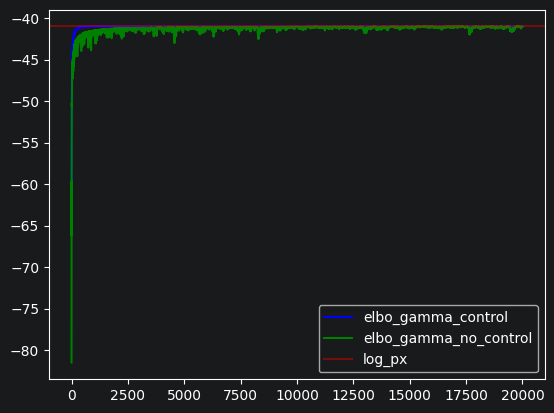

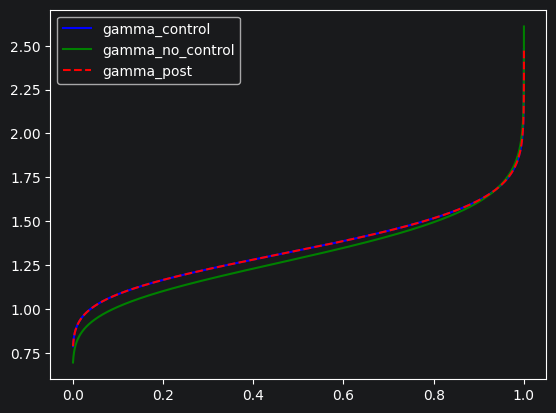

In [7]:
# Insert your code here
S = 50
rate = 0.5
omega0 = [0.0,0.0]
nb_iter = 20000

#Run BBVI
grad_fn = lambda omega,rng : grad_gamma(omega, rng, S, control_variate=True)
adagrad_trace = adagrad_ascent(grad_fn, omega0, nb_iter, rate,rng)
omega_t_control_variate = np.exp(adagrad_trace)

grad_fn = lambda omega,rng : grad_gamma(omega, rng, S, control_variate=False)
adagrad_trace = adagrad_ascent(grad_fn, omega0, nb_iter, rate,rng)
omega_t_no_control_variate = np.exp(adagrad_trace)

#plot the ELBO (`elbo_gamma`) over iterations together with $\log p(x)$ (`log_evidence`)
elbo_gamma_control = elbo_gamma(omega_t_control_variate[:,0], omega_t_control_variate[:,1])
elbo_gamma_no_control = elbo_gamma(omega_t_no_control_variate[:,0],omega_t_no_control_variate[:,1])

log_px = log_evidence()

plt.figure()
plt.plot(elbo_gamma_control,color="blue", label="elbo_gamma_control")
plt.plot(elbo_gamma_no_control,color="green", label="elbo_gamma_no_control")
plt.axhline(log_px,color= "red", alpha= 0.4, label="log_px")
plt.legend()

# report the final $(a,b)$, averaged over the last 2000 iterations, and compare with the exact posterior $\mathrm{Gamma}(\alpha_0+\sum x_n,\ \beta_0+N)$;

a_no_control,b_no_control = omega_t_no_control_variate[-2000:].mean(axis=0)
a_control,b_control = omega_t_control_variate[-2000:].mean(axis=0)

print(f"Real mean : {A_POST/B_POST}")
print(f"Mean for control : {a_control/b_control}")
print(f"Mean for no control : {a_no_control/b_no_control}\n")


print(f"Relative error of a for control : {(a_control-A_POST)/A_POST}")
print(f"Relative error of a for no control :{(a_no_control-A_POST)/A_POST}\n")

print(f"Relative error of b for control : {(b_control-B_POST)/B_POST}")
print(f"Relative error of b for no control : {(b_no_control-B_POST)/B_POST}\n")


# plot the two variational densities together with the exact posterior.

grid = np.linspace(1e-3,1,200000)

gamma_control = gamma_dist.ppf(grid,a=a_control,scale=1/b_control)
gamma_no_control = gamma_dist.ppf(grid,a=a_no_control,scale=1/b_no_control)
gamma_post = gamma_dist.ppf(grid,a=A_POST,scale=1/B_POST)

plt.figure()
plt.plot(grid,gamma_control,color="blue", label="gamma_control")
plt.plot(grid,gamma_no_control,color="green",label="gamma_no_control")
plt.plot(grid,gamma_post,color="red",label="gamma_post",linestyle = "dashed")
plt.legend()



We observe that the coefficients $a$ and $b$ are well estimated when we use the control variates. It is shown in the two plots of the ELBO and of the variational densities.

So, why is the variance lower?

The exact posterior is:

$$
p(\lambda|x) = \mathcal{G}amma\left( \alpha_0 + \sum_n x_n, \beta_0 + N \right)
$$

So, it belongs to the variational family $\mathcal{G}amma(a,b)$. For $a = \alpha_0 + \sum_n x_n$ and $b = \beta_0 + N$, we have $q(\lambda) = p(\lambda|x)$, i.e.,
$$
\mathcal{L}(q) = \log p(x)
$$

So, there isn't any error of approximation due to the choice of the family. The observed error comes from optimization.

If we are at this optimum:

$$
\log p(x,\lambda) - \log q(\lambda) = \log p(x)
$$

And, for each $i$, the estimated gradient at the optimum is:

$$
\hat{g}_i = \log p(x) \frac{1}{S} \sum_{s=1}^S h_i(\lambda_s)
$$

The real gradient is equal to zero, but the mean of the score isn't: there is noise.

With the control variates, at the optimum we have $f_i = \log p(x) h_i$. Each term is corrected, and the gradient is equal to 0:
$$
f_i - c_{i,-s}h_i = 0
$$

Hence, it explains why the naive estimator converges more slowly.